**MOCO 2D**

In [6]:
import digitalhub as dh
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [15]:
job_name = "net_v4"                                     
dataset = "Standard"                                                                       
weights_encoder_sar = "autoencoder_2D_SAR_weights_convLstm_v1"     
weights_encoder_opt = "autoencoder_2D_OPT_weights_convLstm_v1"
                                        

parameters = {
    "job_name": job_name,
    "dataset": dataset,
    "weights_encoder_sar": weights_encoder_sar,
    "weights_encoder_opt": weights_encoder_opt,
    "resume": True, 
    "lr_min": 0.0003,   
    "cosine": True,  
    "simple_proj": False,
    "pool_grid": 4,
    "time_debug": False,   
    "weights_version": "3a4502facfde4b46ab4d6d11dbdd0168",
    "metrics_version": "5022f1d34e5a402d9c8ce5f33e2eef65",

    "epochs": 40, 
    "batch_size": 16,
    "lr": 0.005,
    "weight_decay": 1e-4,
    "momentum": 0.9,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,              
    "n_images2": 4, "n_channels2": 10,              
    "moco_dim": 128,
    "moco_k": 4096,                                     
    "moco_t": 0.07,
    "hidden_channels_dim": 64,
    "symmetric": False,
    "workers": 0,
    "patience": 40,
    "min_delta": 1e-4,                                   
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",      
        "spec": {"size": "400Gi"}   
    }
]

**BUILD ENVIRONMENT**

In [16]:
moco_func = project.new_function(
    name=f'net_v4',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="moco:train_moco_2D",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [ ]:
resources = {"cpu": "4", "mem": "20Gi"}

run_moco_2D = moco_func.run(
    action="job", 
    parameters=parameters, 
    volumes=volumes, 
    resources=resources,
    profile="1xv100-shared",
    local_execution= False,                       
    wait=True
)

print(f"Run moco avviato: {run_moco_2D.id}")

2026-11-04 12:26:49,330 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 25fdae95121b43b69df8cb002cc1c8c7 to finish...
2026-11-04 12:26:54,338 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 25fdae95121b43b69df8cb002cc1c8c7 to finish...
2026-11-04 12:26:59,347 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 25fdae95121b43b69df8cb002cc1c8c7 to finish...
2026-11-04 12:27:04,359 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 25fdae95121b43b69df8cb002cc1c8c7 to finish...
2026-11-04 12:27:09,367 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 25fdae95121b43b69df8cb002cc1c8c7 to finish...
2026-11-04 12:27:14,378 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 25fdae95121b43b69df8cb002cc1c8c7 to finish...
2026-11-04 12:27:19,386 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 25fdae95121b43b69df8cb002cc1c8c7 to finish...
2026-11-04 12

**PLOTS**

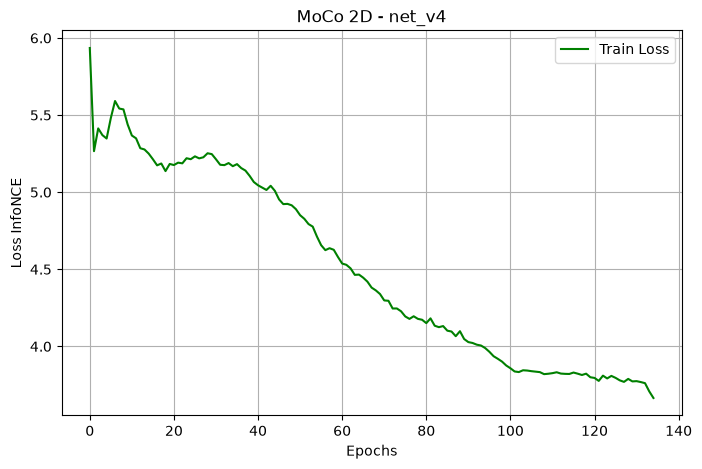

In [ ]:
path = project.get_artifact(f"moco_2D_metrics_{job_name}").download(overwrite=True)
df = pd.read_csv(path)

plt.figure(figsize=(8, 5))
plt.plot(df['epoch'], df['train_loss'], color='green', label='Train Loss')
plt.title(f'MoCo 2D - {job_name}')
plt.xlabel('Epochs')
plt.ylabel('Loss InfoNCE')
plt.grid(True)
plt.legend()
plt.show()